# Seminar 3: Exploratory Data Analysis & OLS Regression (Titanic Dataset)

### Objectives:
1. **Data Ingestion & Integrity Audit**: Audit data types, missing values, duplicates, and initial summary statistics.
2. **Univariate Analysis**: Examine the distributions, skewness, and outliers of individual features.
3. **Feature Engineering for EDA**: Derive family dynamics (`FamilySize`, `IsAlone`), title parsing (`Title`), and fare transformations (`LogFare`).
4. **Bivariate & Multivariate Relationships**: Explore interactions and correlations with survival outcomes (`Survived`) and passenger socioeconomics.
5. **Ordinary Least Squares (OLS) Regressions**:
   - Linear Probability Models (LPM) regressing `Survived` on categorical and continuous predictors.
   - Socioeconomic pricing models regressing `Fare` on class, demographics, and cabin characteristics.
6. **Diagnostics & Forest Plots**: Quantify coefficient sizes, confidence intervals, p-values, and model residuals.

> *Note: All exploratory computations, visualisations, and regression models are executed below, structured for analysis and interpretation.*

## 1. Environment & Library Setup

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("Environment configured and libraries loaded successfully.")

Environment configured and libraries loaded successfully.


## 2. Data Ingestion & Schema Audit

In [52]:
# Load Titanic dataset
df = pd.read_csv('titanic.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head(10))

Dataset Dimensions: 891 rows, 12 columns



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0000,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0000,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0000,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0000,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0000,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0000,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0000,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0000,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0000,1,0,237736,30.0708,NaN,C


In [53]:
# Column schema and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 3. Data Completeness & Integrity Checks

,Missing Count,Missing Pct (%),Data Type
Cabin,687,77.1044,str
Age,177,19.8653,float64
Embarked,2,0.2245,str


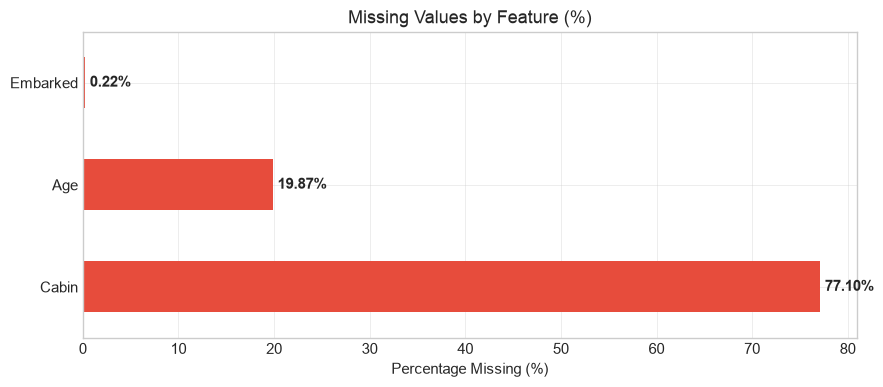

In [54]:
# Missing values audit
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Pct (%)': missing_pct,
    'Data Type': df.dtypes
}).sort_values(by='Missing Count', ascending=False)

display(missing_df[missing_df['Missing Count'] > 0])

# Missingness horizontal bar visualization
fig, ax = plt.subplots(figsize=(9, 4))
missing_plot_data = missing_df[missing_df['Missing Count'] > 0]['Missing Pct (%)']
missing_plot_data.plot(kind='barh', color='#e74c3c', ax=ax)
ax.set_title('Missing Values by Feature (%)', fontsize=13)
ax.set_xlabel('Percentage Missing (%)')
for i, v in enumerate(missing_plot_data):
    ax.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [55]:
# Duplication and cardinality inspection
print(f"Total duplicate rows: {df.duplicated().sum()}")

cardinality_df = pd.DataFrame({
    'Unique Count': df.nunique(),
    'Sample Values': [df[col].dropna().unique()[:3].tolist() for col in df.columns]
})
display(cardinality_df)

Total duplicate rows: 0


,Unique Count,Sample Values
PassengerId,891,"[1, 2, 3]"
Survived,2,"[0, 1]"
Pclass,3,"[3, 1, 2]"
Name,891,"[Braund, Mr. Owen Harris, Cumings, Mrs. John B..."
Sex,2,"[male, female]"
Age,88,"[22.0, 38.0, 26.0]"
SibSp,7,"[1, 0, 3]"
Parch,7,"[0, 1, 2]"
Ticket,681,"[A/5 21171, PC 17599, STON/O2. 3101282]"
Fare,248,"[7.25, 71.2833, 7.925]"


## 4. Summary Statistics (Descriptive Analysis)

In [56]:
# Numerical summary statistics with skewness and IQR
num_summary = df.describe().T
num_summary['median'] = df.median(numeric_only=True)
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
num_summary['skewness'] = df.skew(numeric_only=True)

display(num_summary[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'IQR', 'skewness']])

,count,mean,std,min,25%,median,75%,max,IQR,skewness
PassengerId,891.0000,446.0000,257.3538,1.0000,223.5000,446.0000,668.5000,891.0000,445.0000,0.0000
Survived,891.0000,0.3838,0.4866,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,0.4785
Pclass,891.0000,2.3086,0.8361,1.0000,2.0000,3.0000,3.0000,3.0000,1.0000,-0.6305
Age,714.0000,29.6991,14.5265,0.4200,20.1250,28.0000,38.0000,80.0000,17.8750,0.3891
SibSp,891.0000,0.5230,1.1027,0.0000,0.0000,0.0000,1.0000,8.0000,1.0000,3.6954
Parch,891.0000,0.3816,0.8061,0.0000,0.0000,0.0000,0.0000,6.0000,0.0000,2.7491
Fare,891.0000,32.2042,49.6934,0.0000,7.9104,14.4542,31.0000,512.3292,23.0896,4.7873


In [57]:
# Categorical summary statistics
display(df.describe(include=['object', 'str']).T)

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


## 5. Univariate Feature Distributions

/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_4101/865214567.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Perished (0)', 'Survived (1)'])


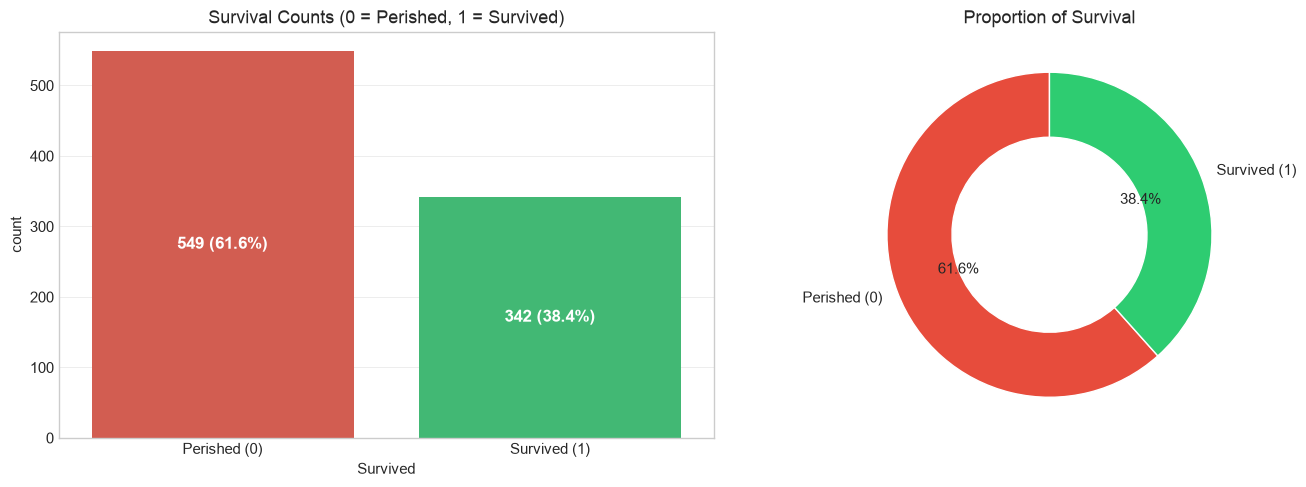

In [58]:
# Target variable distribution: Survived
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Survival counts bar plot
sns.countplot(x='Survived', data=df, palette=['#e74c3c', '#2ecc71'], ax=axes[0], hue='Survived', legend=False)
axes[0].set_title('Survival Counts (0 = Perished, 1 = Survived)', fontsize=13)
axes[0].set_xticklabels(['Perished (0)', 'Survived (1)'])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=12, color='white', weight='bold')

# Survival proportion donut chart
survived_counts = df['Survived'].value_counts()
axes[1].pie(survived_counts, labels=['Perished (0)', 'Survived (1)'], autopct='%1.1f%%',
            startangle=90, colors=['#e74c3c', '#2ecc71'], wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title('Proportion of Survival', fontsize=13)

plt.tight_layout()
plt.show()

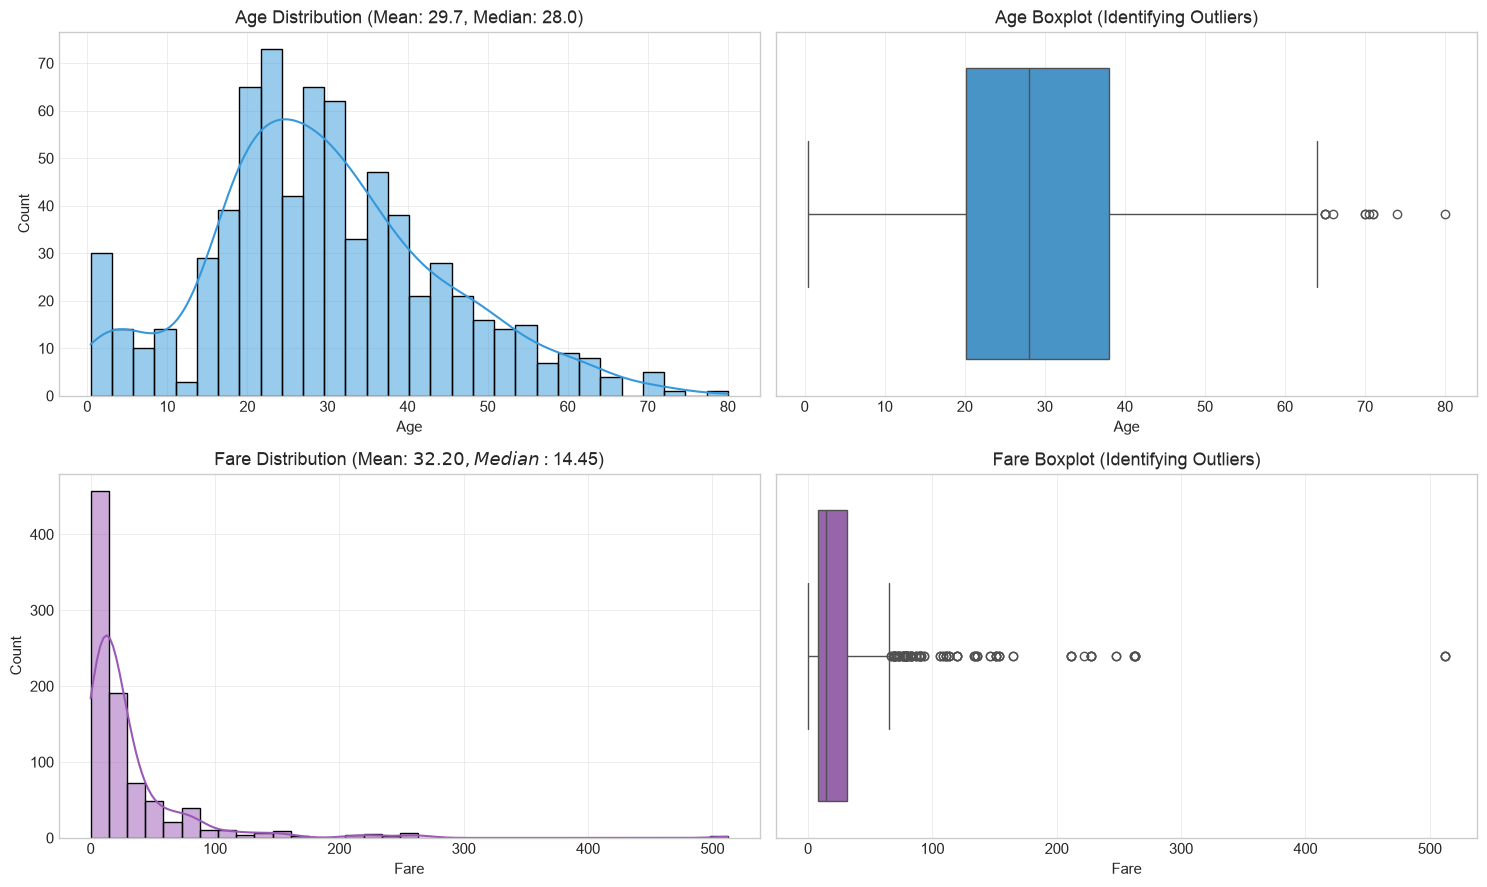

In [59]:
# Continuous numerical distributions: Age and Fare
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Age Histogram & KDE
sns.histplot(df['Age'].dropna(), kde=True, ax=axes[0, 0], color='#3498db', bins=30)
axes[0, 0].set_title(f"Age Distribution (Mean: {df['Age'].mean():.1f}, Median: {df['Age'].median():.1f})")

# Age Boxplot
sns.boxplot(x=df['Age'], ax=axes[0, 1], color='#3498db')
axes[0, 1].set_title('Age Boxplot (Identifying Outliers)')

# Fare Histogram & KDE
sns.histplot(df['Fare'], kde=True, ax=axes[1, 0], color='#9b59b6', bins=35)
axes[1, 0].set_title(f"Fare Distribution (Mean: ${df['Fare'].mean():.2f}, Median: ${df['Fare'].median():.2f})")

# Fare Boxplot
sns.boxplot(x=df['Fare'], ax=axes[1, 1], color='#9b59b6')
axes[1, 1].set_title('Fare Boxplot (Identifying Outliers)')

plt.tight_layout()
plt.show()

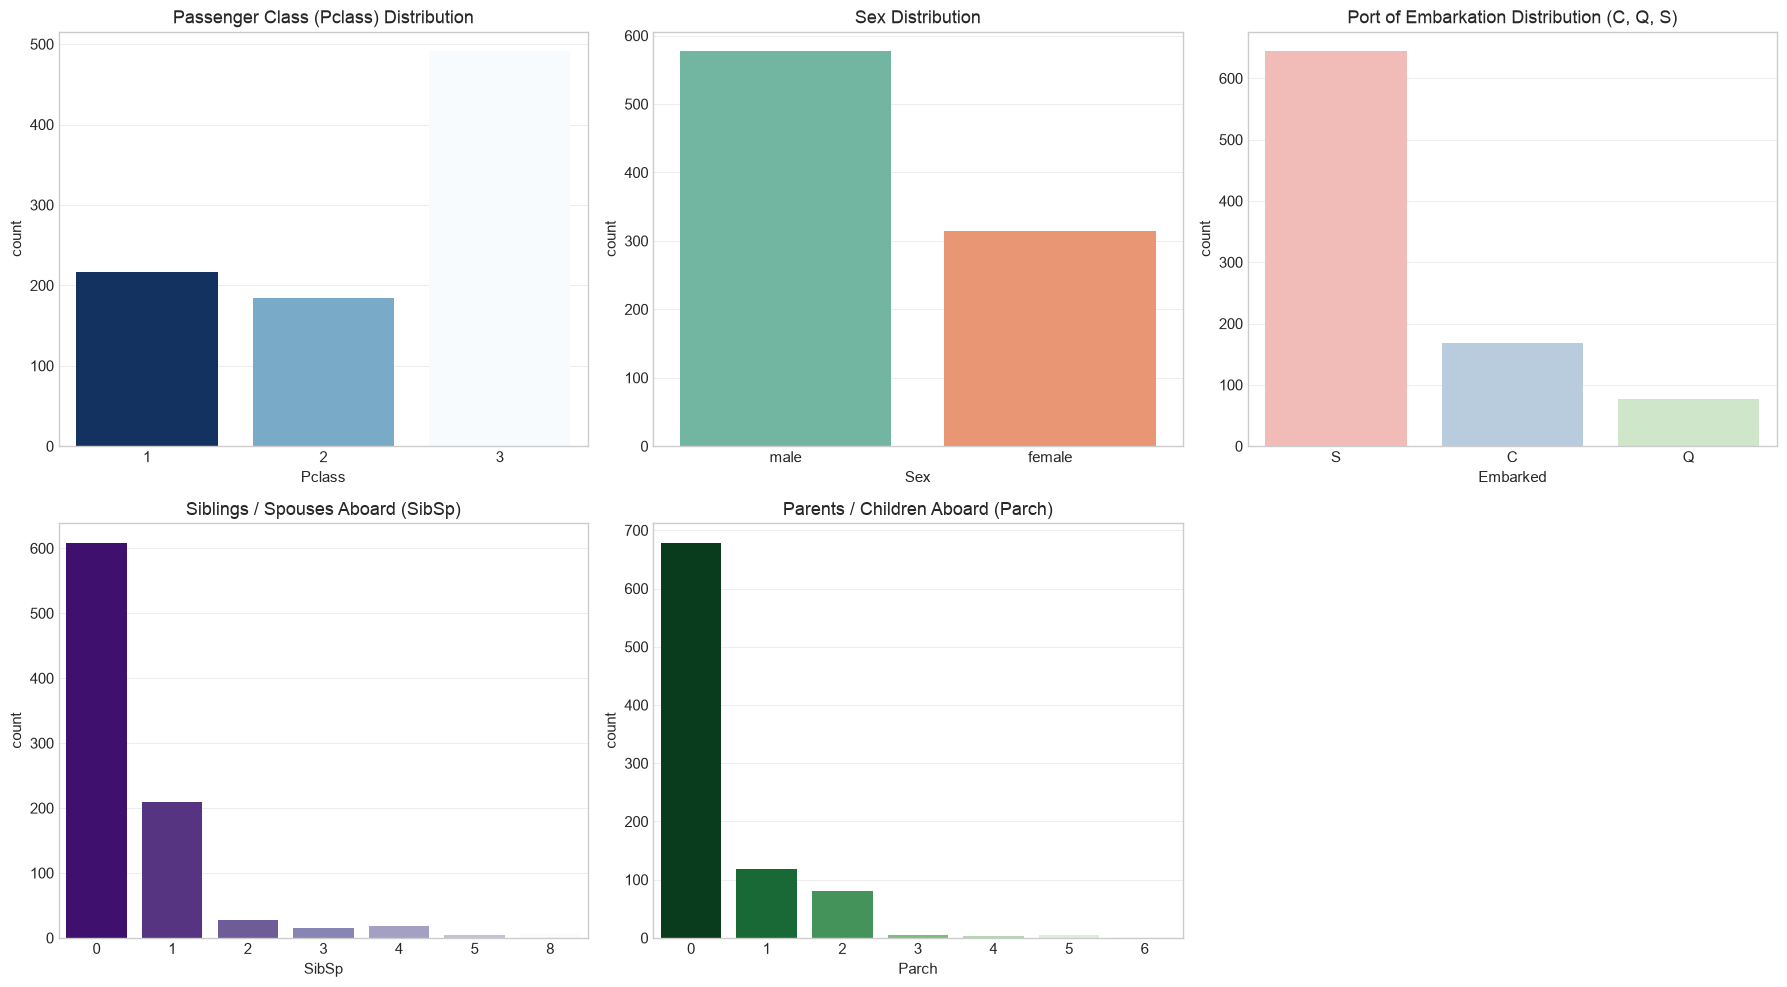

In [60]:
# Categorical and discrete feature counts
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.countplot(x='Pclass', data=df, palette='Blues_r', ax=axes[0, 0], hue='Pclass', legend=False)
axes[0, 0].set_title('Passenger Class (Pclass) Distribution')

sns.countplot(x='Sex', data=df, palette='Set2', ax=axes[0, 1], hue='Sex', legend=False)
axes[0, 1].set_title('Sex Distribution')

sns.countplot(x='Embarked', data=df, palette='Pastel1', ax=axes[0, 2], hue='Embarked', legend=False)
axes[0, 2].set_title('Port of Embarkation Distribution (C, Q, S)')

sns.countplot(x='SibSp', data=df, palette='Purples_r', ax=axes[1, 0], hue='SibSp', legend=False)
axes[1, 0].set_title('Siblings / Spouses Aboard (SibSp)')

sns.countplot(x='Parch', data=df, palette='Greens_r', ax=axes[1, 1], hue='Parch', legend=False)
axes[1, 1].set_title('Parents / Children Aboard (Parch)')

axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

## 6. Feature Engineering for In-Depth Exploration

We construct derived variables to support our relationship and regression analyses:
- `FamilySize`: Total traveling group size (`SibSp + Parch + 1`)
- `IsAlone`: Indicator variable for solo travelers (`FamilySize == 1`)
- `Title`: Extracted honorific/title from `Name` (e.g. Mr, Mrs, Miss, Master)
- `Deck`: First character of `Cabin` (or `Unknown` if missing)
- `LogFare`: Natural logarithm of `Fare + 1` to stabilize high positive skewness

In [61]:
df_feat = df.copy()

# 1. Family Size & Solo Status
df_feat['FamilySize'] = df_feat['SibSp'] + df_feat['Parch'] + 1
df_feat['IsAlone'] = (df_feat['FamilySize'] == 1).astype(int)

# 2. Extract Title from Name
df_feat['Title'] = df_feat['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
common_titles = ['Mr', 'Miss', 'Mrs', 'Master']
df_feat['Title_Grouped'] = df_feat['Title'].apply(lambda x: x if x in common_titles else 'Rare')

# 3. Cabin Deck
df_feat['Deck'] = df_feat['Cabin'].str[0].fillna('Unknown')

# 4. Log Transformation of Fare
df_feat['LogFare'] = np.log1p(df_feat['Fare'])

# 5. Age Binning for tabular comparisons
df_feat['AgeGroup'] = pd.cut(df_feat['Age'], bins=[0, 12, 18, 35, 60, 100], 
                             labels=['Child (0-12)', 'Teen (13-18)', 'Young Adult (19-35)', 'Adult (36-60)', 'Senior (61+)'])

display(df_feat[['PassengerId', 'Name', 'Title_Grouped', 'FamilySize', 'IsAlone', 'Deck', 'LogFare', 'AgeGroup']].head(8))

,PassengerId,Name,Title_Grouped,FamilySize,IsAlone,Deck,LogFare,AgeGroup
0,1,"Braund, Mr. Owen Harris",Mr,2,0,Unknown,2.1102,Young Adult (19-35)
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,C,4.2806,Adult (36-60)
2,3,"Heikkinen, Miss. Laina",Miss,1,1,Unknown,2.1889,Young Adult (19-35)
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,C,3.9908,Young Adult (19-35)
4,5,"Allen, Mr. William Henry",Mr,1,1,Unknown,2.2028,Young Adult (19-35)
5,6,"Moran, Mr. James",Mr,1,1,Unknown,2.2469,NaN
6,7,"McCarthy, Mr. Timothy J",Mr,1,1,E,3.9677,Adult (36-60)
7,8,"Palsson, Master. Gosta Leonard",Master,5,0,Unknown,3.0944,Child (0-12)


## 7. Bivariate & Multivariate Relationship Analysis

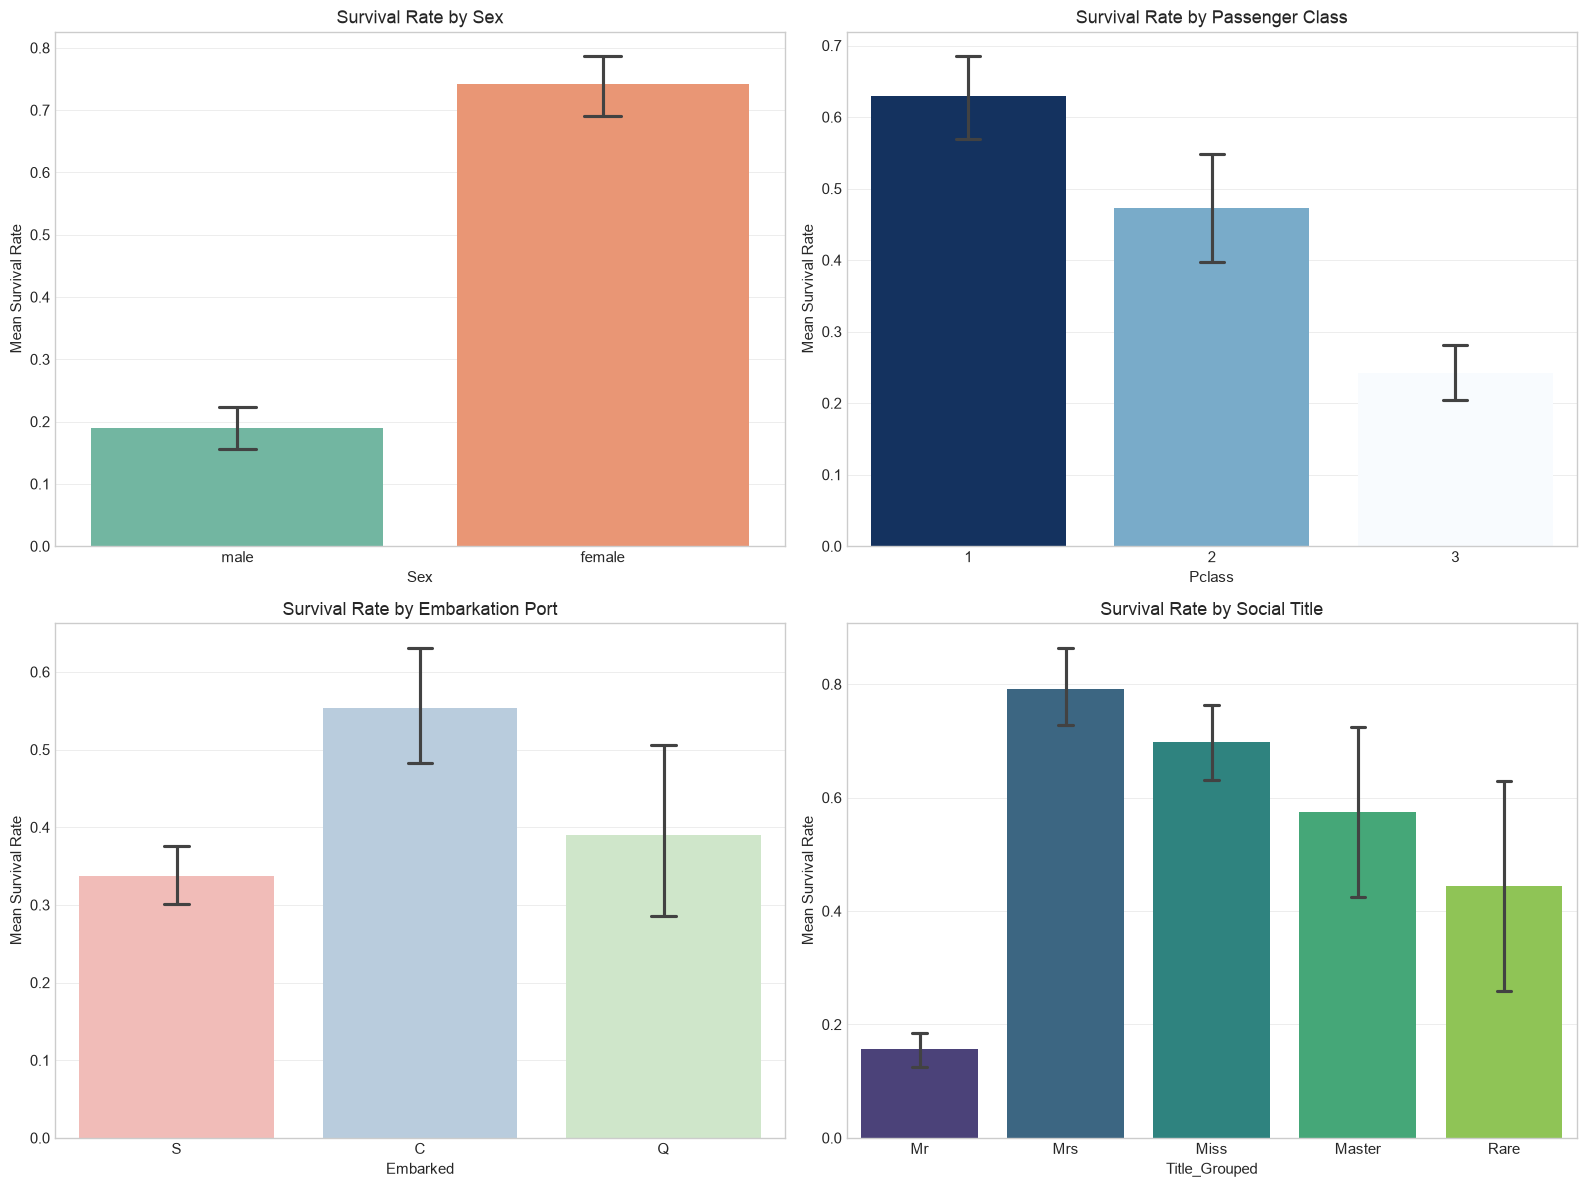

In [62]:
# Categorical predictors vs. Survival Rate
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Sex vs Survived
sns.barplot(x='Sex', y='Survived', data=df_feat, palette='Set2', ax=axes[0, 0], capsize=0.1, hue='Sex', legend=False)
axes[0, 0].set_title('Survival Rate by Sex')
axes[0, 0].set_ylabel('Mean Survival Rate')

# Pclass vs Survived
sns.barplot(x='Pclass', y='Survived', data=df_feat, palette='Blues_r', ax=axes[0, 1], capsize=0.1, hue='Pclass', legend=False)
axes[0, 1].set_title('Survival Rate by Passenger Class')
axes[0, 1].set_ylabel('Mean Survival Rate')

# Embarked vs Survived
sns.barplot(x='Embarked', y='Survived', data=df_feat, palette='Pastel1', ax=axes[1, 0], capsize=0.1, hue='Embarked', legend=False)
axes[1, 0].set_title('Survival Rate by Embarkation Port')
axes[1, 0].set_ylabel('Mean Survival Rate')

# Title Grouped vs Survived
sns.barplot(x='Title_Grouped', y='Survived', data=df_feat, palette='viridis', ax=axes[1, 1], capsize=0.1, hue='Title_Grouped', legend=False)
axes[1, 1].set_title('Survival Rate by Social Title')
axes[1, 1].set_ylabel('Mean Survival Rate')

plt.tight_layout()
plt.show()

In [63]:
# Demographic interaction cross-tabulations
print("Survival Percentage by Sex:")
display(pd.crosstab(df_feat['Sex'], df_feat['Survived'], normalize='index', margins=True).round(4) * 100)

print("\nSurvival Percentage by Class and Sex:")
display(pd.crosstab([df_feat['Pclass'], df_feat['Sex']], df_feat['Survived'], normalize='index', margins=True).round(4) * 100)

print("\nSurvival Percentage by Age Group:")
display(pd.crosstab(df_feat['AgeGroup'], df_feat['Survived'], normalize='index', margins=True).round(4) * 100)

Survival Percentage by Sex:


Survived,0,1
Sex,,
female,25.8000,74.2000
male,81.1100,18.8900
All,61.6200,38.3800



Survival Percentage by Class and Sex:


Survived            0       1
Pclass Sex                   
1      female  3.1900 96.8100
       male   63.1100 36.8900
2      female  7.8900 92.1100
       male   84.2600 15.7400
3      female 50.0000 50.0000
       male   86.4600 13.5400
All           61.6200 38.3800


Survival Percentage by Age Group:


Survived,0,1
AgeGroup,,
Child (0-12),42.0300,57.9700
Teen (13-18),57.1400,42.8600
Young Adult (19-35),61.7300,38.2700
Adult (36-60),60.0000,40.0000
Senior (61+),77.2700,22.7300
All,59.3800,40.6200


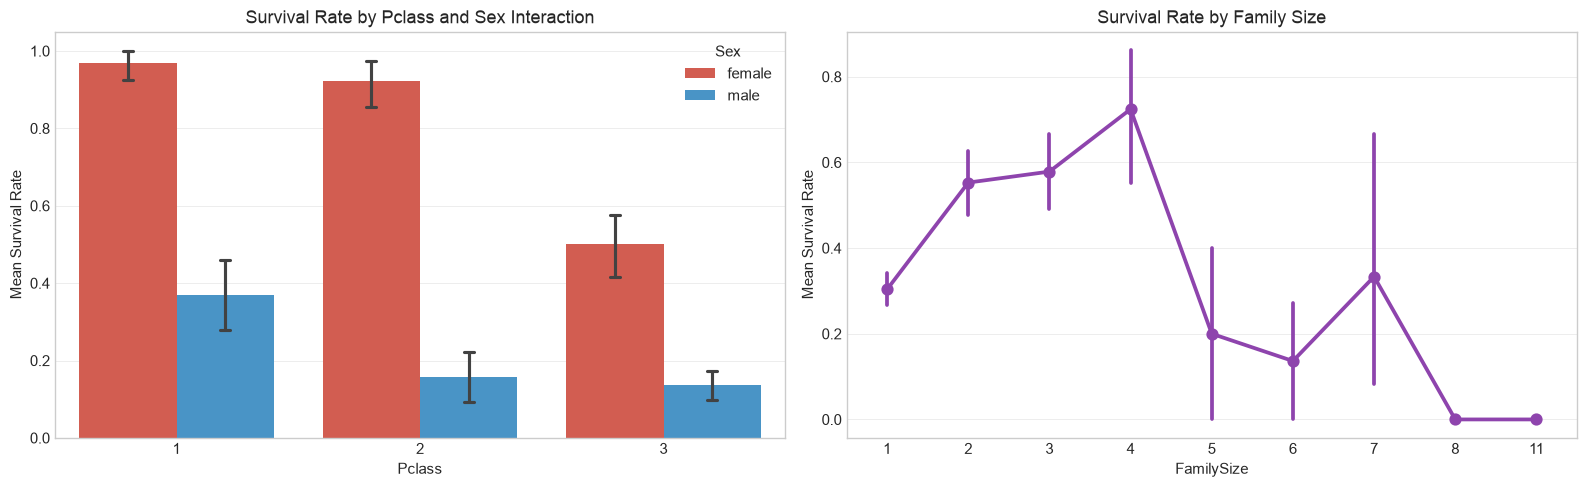

In [64]:
# Multi-dimensional interactions: Class x Sex, and Family Dynamics
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Pclass x Sex interaction
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df_feat, palette={'male': '#3498db', 'female': '#e74c3c'}, ax=axes[0], capsize=0.08)
axes[0].set_title('Survival Rate by Pclass and Sex Interaction')
axes[0].set_ylabel('Mean Survival Rate')

# Family Size vs Survival Rate
sns.pointplot(x='FamilySize', y='Survived', data=df_feat, color='#8e44ad', ax=axes[1], markers='o')
axes[1].set_title('Survival Rate by Family Size')
axes[1].set_ylabel('Mean Survival Rate')

plt.tight_layout()
plt.show()

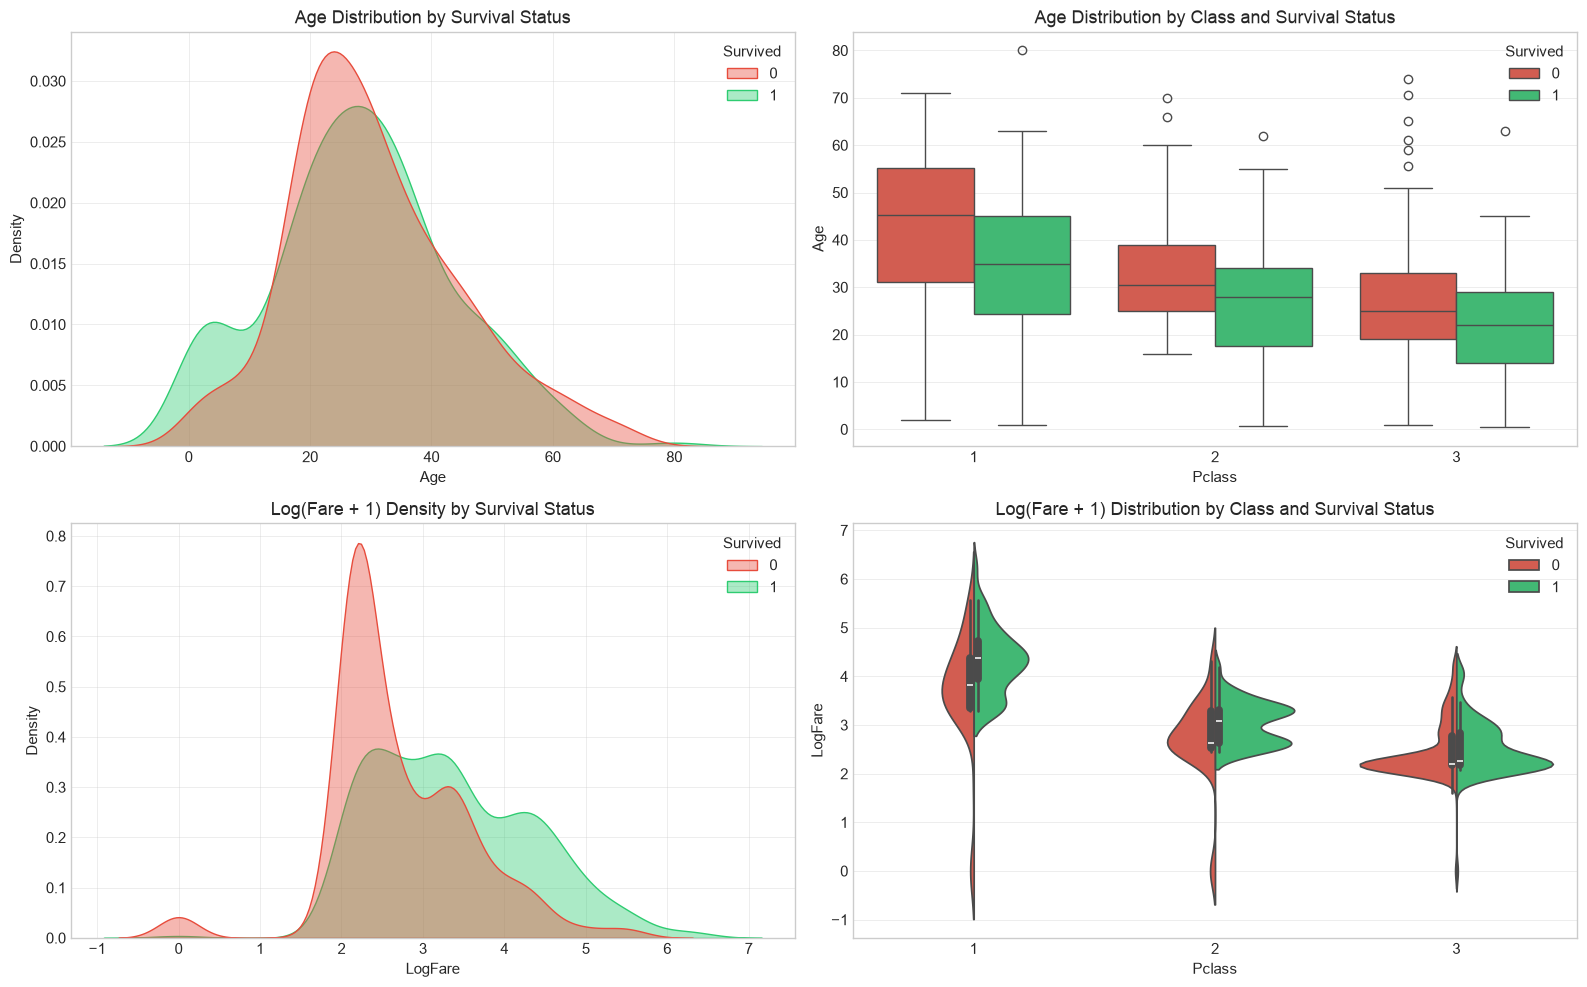

In [65]:
# Continuous predictors vs. Survival
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Age KDE by Survival
sns.kdeplot(data=df_feat, x='Age', hue='Survived', common_norm=False, fill=True, alpha=0.4, palette=['#e74c3c', '#2ecc71'], ax=axes[0, 0])
axes[0, 0].set_title('Age Distribution by Survival Status')

# Age Boxplot by Class and Survival
sns.boxplot(x='Pclass', y='Age', hue='Survived', data=df_feat, palette=['#e74c3c', '#2ecc71'], ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution by Class and Survival Status')

# LogFare KDE by Survival
sns.kdeplot(data=df_feat, x='LogFare', hue='Survived', common_norm=False, fill=True, alpha=0.4, palette=['#e74c3c', '#2ecc71'], ax=axes[1, 0])
axes[1, 0].set_title('Log(Fare + 1) Density by Survival Status')

# LogFare Violin plot by Class and Survival
sns.violinplot(x='Pclass', y='LogFare', hue='Survived', data=df_feat, split=True, palette=['#e74c3c', '#2ecc71'], ax=axes[1, 1])
axes[1, 1].set_title('Log(Fare + 1) Distribution by Class and Survival Status')

plt.tight_layout()
plt.show()

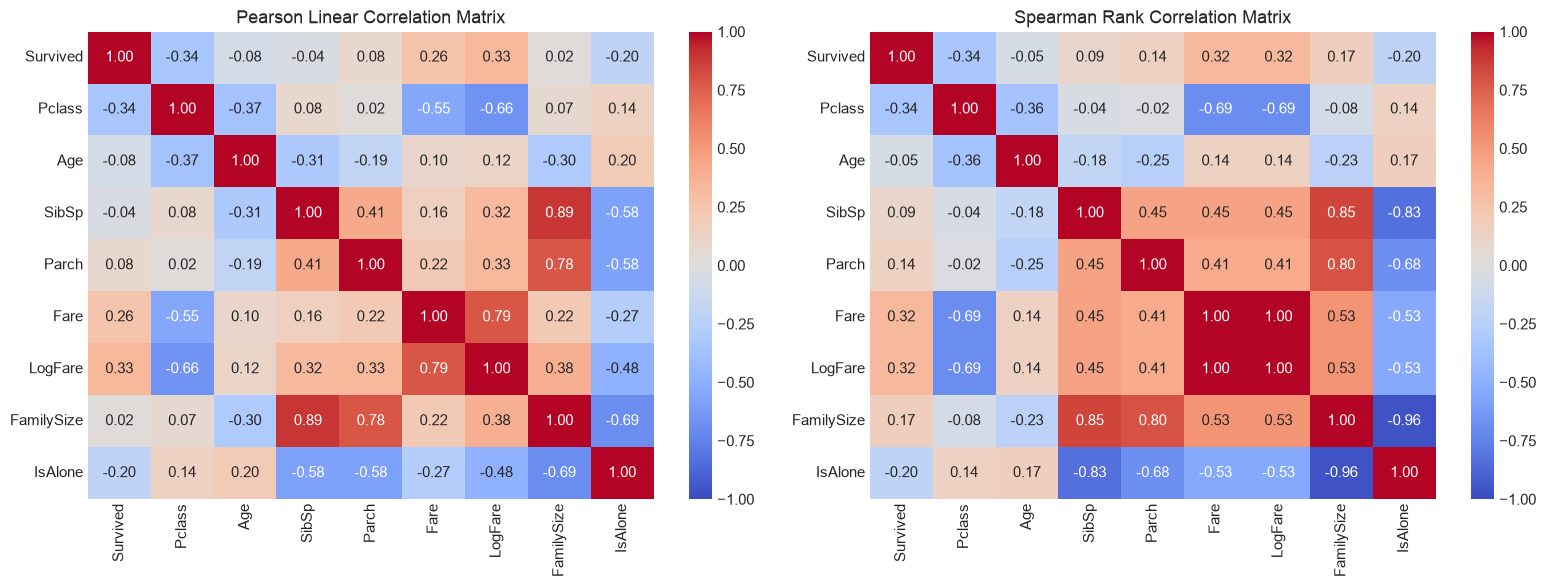

In [66]:
# Correlation Matrices (Pearson vs Spearman)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'LogFare', 'FamilySize', 'IsAlone']

# Pearson correlation (linear)
sns.heatmap(df_feat[corr_cols].corr(method='pearson'), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson Linear Correlation Matrix')

# Spearman rank correlation (monotonic)
sns.heatmap(df_feat[corr_cols].corr(method='spearman'), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman Rank Correlation Matrix')

plt.tight_layout()
plt.show()

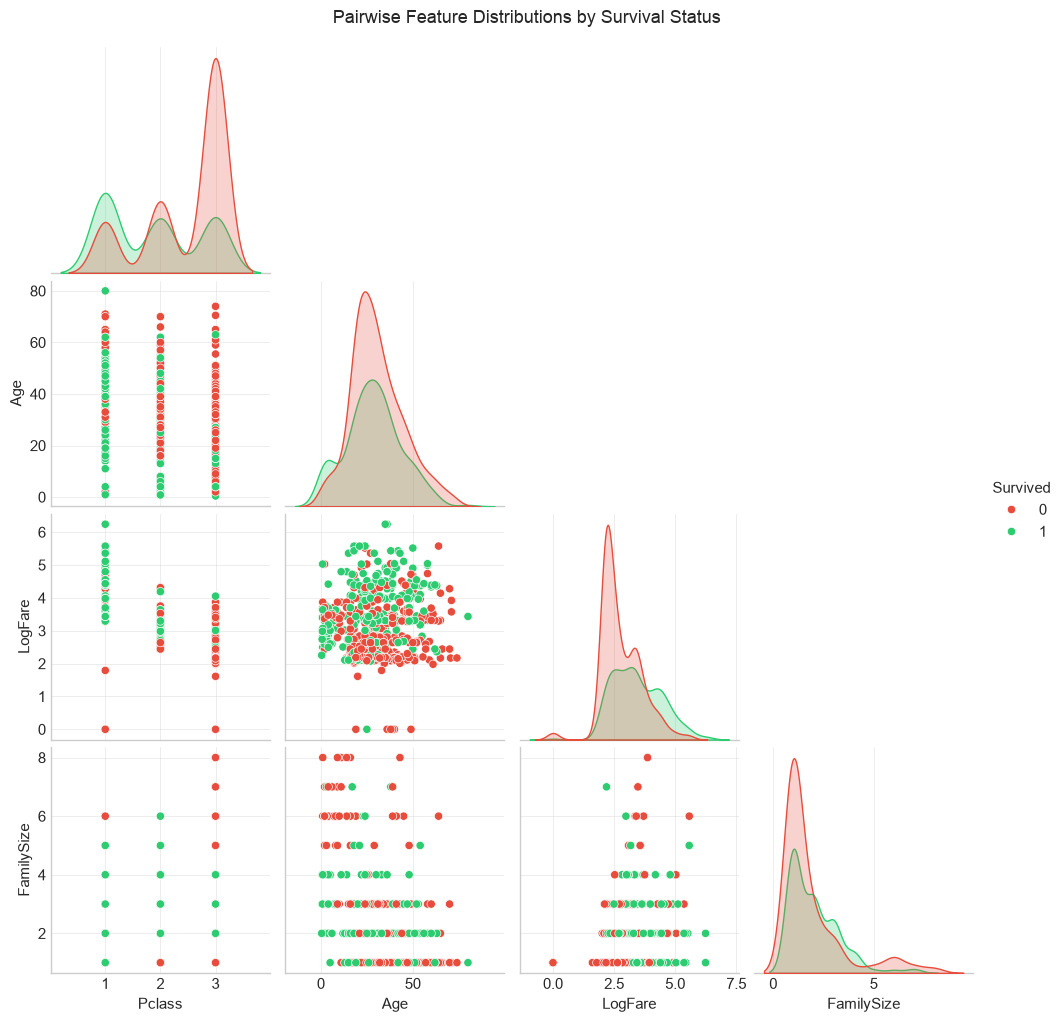

In [67]:
# Pairwise scatter & distribution grid
pair_vars = ['Survived', 'Pclass', 'Age', 'LogFare', 'FamilySize']
grid = sns.pairplot(df_feat[pair_vars].dropna(), hue='Survived', palette=['#e74c3c', '#2ecc71'], corner=True, diag_kind='kde')
grid.fig.suptitle('Pairwise Feature Distributions by Survival Status', y=1.02)
plt.show()

## 8. Ordinary Least Squares (OLS) Regression Analysis

In this section, we apply OLS regression models to investigate relationships:
1. **Linear Probability Models (LPM)** for binary outcome `Survived`:
   - Regressing `Survived` directly on predictors using OLS allows intuitive marginal probability interpretations: each coefficient $\beta_j$ represents the percentage point change in survival probability associated with a one-unit change in $X_j$, holding all other factors constant.
2. **Class & Sex Interaction Model**:
   - Testing whether the effect of passenger class on survival differed between male and female passengers.
3. **Continuous Pricing Model**:
   - Determinants of ticket prices (`LogFare`) based on passenger class, demographics, embarkation port, and family party size.

In [68]:
# OLS Model 1: Baseline Linear Probability Model
ols_m1 = smf.ols(formula="Survived ~ C(Pclass) + C(Sex) + Age", data=df_feat).fit()
print("=================== OLS MODEL 1: BASELINE LPM ===================")
print(ols_m1.summary())

=================== OLS MODEL 1: BASELINE LPM ===================
                            OLS Regression Results                            
Dep. Variable:               Survived   R-squared:                       0.390
Model:                            OLS   Adj. R-squared:                  0.387
Method:                 Least Squares   F-statistic:                     113.4
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           9.96e-75
Time:                        10:23:49   Log-Likelihood:                -328.84
No. Observations:                 714   AIC:                             667.7
Df Residuals:                     709   BIC:                             690.5
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

In [69]:
# OLS Model 2: Comprehensive Multivariate LPM
ols_m2 = smf.ols(
    formula="Survived ~ C(Pclass) + C(Sex) + Age + SibSp + Parch + LogFare + C(Embarked)",
    data=df_feat
).fit()
print("=================== OLS MODEL 2: MULTIVARIATE LPM ===================")
print(ols_m2.summary())

=================== OLS MODEL 2: MULTIVARIATE LPM ===================
                            OLS Regression Results                            
Dep. Variable:               Survived   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.394
Method:                 Least Squares   F-statistic:                     52.27
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.93e-72
Time:                        10:23:49   Log-Likelihood:                -320.94
No. Observations:                 712   AIC:                             661.9
Df Residuals:                     702   BIC:                             707.6
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------

In [70]:
# OLS Model 3: Interaction LPM (Class x Sex Interaction)
ols_m3 = smf.ols(
    formula="Survived ~ C(Pclass) * C(Sex) + Age + SibSp + Parch + LogFare",
    data=df_feat
).fit()
print("=================== OLS MODEL 3: INTERACTION LPM ===================")
print(ols_m3.summary())

=================== OLS MODEL 3: INTERACTION LPM ===================
                            OLS Regression Results                            
Dep. Variable:               Survived   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.428
Method:                 Least Squares   F-statistic:                     60.24
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           2.02e-81
Time:                        10:23:49   Log-Likelihood:                -301.56
No. Observations:                 714   AIC:                             623.1
Df Residuals:                     704   BIC:                             668.8
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

In [71]:
# OLS Model 4: Determinants of Ticket Pricing (Continuous Outcome)
ols_m4 = smf.ols(
    formula="LogFare ~ C(Pclass) + Age + C(Sex) + SibSp + Parch + C(Embarked)",
    data=df_feat
).fit()
print("=================== OLS MODEL 4: DETERMINANTS OF LOG(FARE) ===================")
print(ols_m4.summary())

=================== OLS MODEL 4: DETERMINANTS OF LOG(FARE) ===================
                            OLS Regression Results                            
Dep. Variable:                LogFare   R-squared:                       0.718
Model:                            OLS   Adj. R-squared:                  0.715
Method:                 Least Squares   F-statistic:                     223.6
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          1.93e-187
Time:                        10:23:50   Log-Likelihood:                -523.64
No. Observations:                 712   AIC:                             1065.
Df Residuals:                     703   BIC:                             1106.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------

## 9. Regression Visualisations & Diagnostic Plots

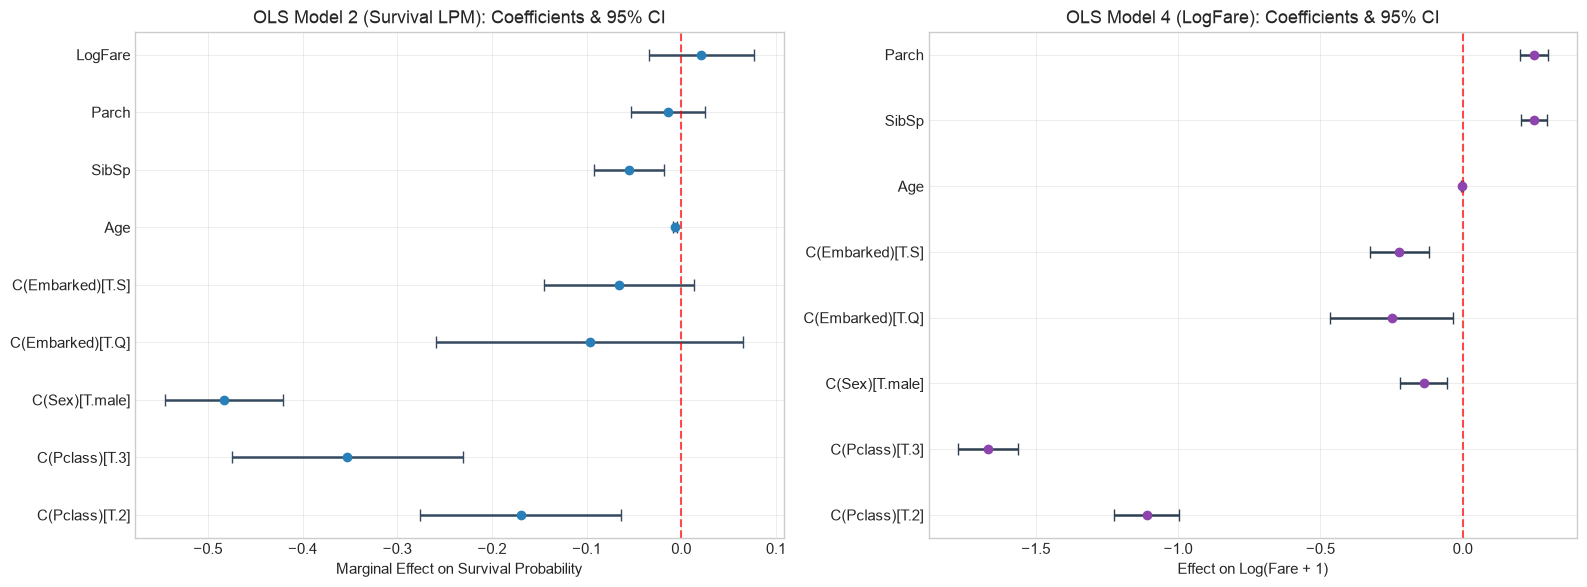

In [72]:
# Coefficient Forest Plots (Estimated Effects & 95% Confidence Intervals)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Survival LPM Model 2 Forest Plot
coef_surv = pd.DataFrame({
    'coef': ols_m2.params,
    'ci_lower': ols_m2.conf_int()[0],
    'ci_upper': ols_m2.conf_int()[1]
}).drop(index='Intercept')

y_pos1 = np.arange(len(coef_surv))
axes[0].errorbar(coef_surv['coef'], y_pos1, 
                 xerr=[coef_surv['coef'] - coef_surv['ci_lower'], coef_surv['ci_upper'] - coef_surv['coef']], 
                 fmt='o', color='#2980b9', ecolor='#34495e', capsize=4, elinewidth=1.8, markersize=6)
axes[0].axvline(0, color='red', linestyle='--', alpha=0.7)
axes[0].set_yticks(y_pos1)
axes[0].set_yticklabels(coef_surv.index)
axes[0].set_title('OLS Model 2 (Survival LPM): Coefficients & 95% CI')
axes[0].set_xlabel('Marginal Effect on Survival Probability')

# Pricing Model 4 Forest Plot
coef_fare = pd.DataFrame({
    'coef': ols_m4.params,
    'ci_lower': ols_m4.conf_int()[0],
    'ci_upper': ols_m4.conf_int()[1]
}).drop(index='Intercept')

y_pos2 = np.arange(len(coef_fare))
axes[1].errorbar(coef_fare['coef'], y_pos2, 
                 xerr=[coef_fare['coef'] - coef_fare['ci_lower'], coef_fare['ci_upper'] - coef_fare['coef']], 
                 fmt='o', color='#8e44ad', ecolor='#2c3e50', capsize=4, elinewidth=1.8, markersize=6)
axes[1].axvline(0, color='red', linestyle='--', alpha=0.7)
axes[1].set_yticks(y_pos2)
axes[1].set_yticklabels(coef_fare.index)
axes[1].set_title('OLS Model 4 (LogFare): Coefficients & 95% CI')
axes[1].set_xlabel('Effect on Log(Fare + 1)')

plt.tight_layout()
plt.show()

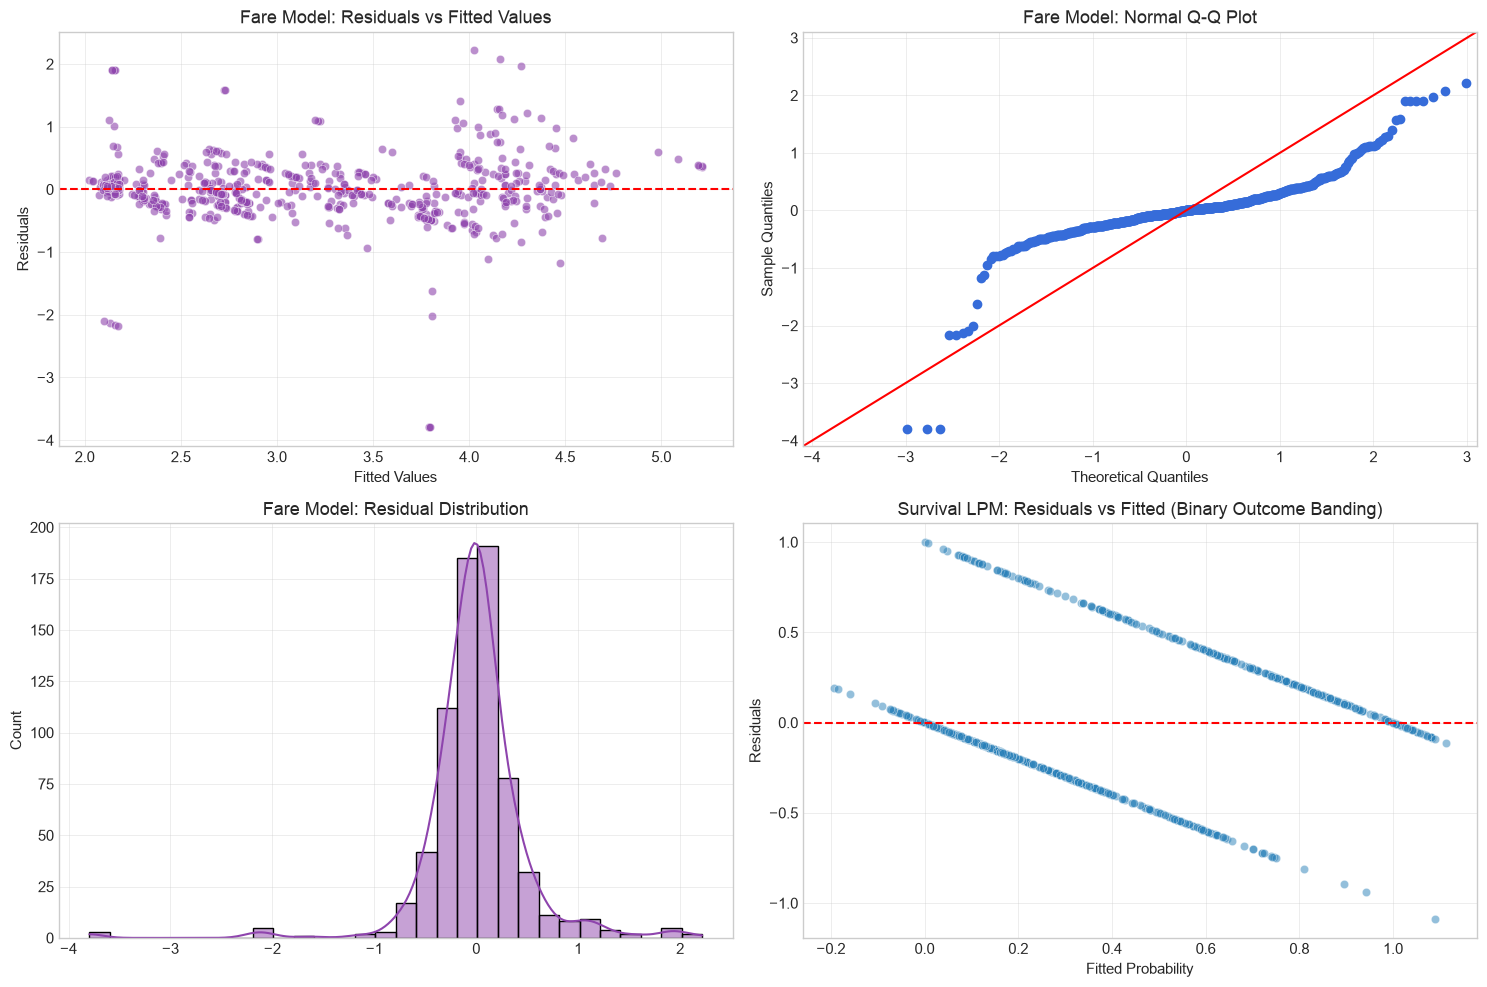

In [73]:
# Residual Diagnostics for Continuous Model (Model 4) and LPM (Model 2)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Model 4: Residuals vs Fitted
fitted_fare = ols_m4.fittedvalues
resid_fare = ols_m4.resid
sns.scatterplot(x=fitted_fare, y=resid_fare, alpha=0.6, ax=axes[0, 0], color='#8e44ad')
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title('Fare Model: Residuals vs Fitted Values')
axes[0, 0].set_xlabel('Fitted Values')
axes[0, 0].set_ylabel('Residuals')

# Model 4: Normal Q-Q Plot
sm.qqplot(resid_fare, line='45', ax=axes[0, 1])
axes[0, 1].set_title('Fare Model: Normal Q-Q Plot')

# Model 4: Residual Distribution
sns.histplot(resid_fare, kde=True, ax=axes[1, 0], color='#8e44ad', bins=30)
axes[1, 0].set_title('Fare Model: Residual Distribution')

# Model 2: LPM Residuals vs Fitted (Banded structure expected in LPM)
fitted_surv = ols_m2.fittedvalues
resid_surv = ols_m2.resid
sns.scatterplot(x=fitted_surv, y=resid_surv, alpha=0.5, ax=axes[1, 1], color='#2980b9')
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].set_title('Survival LPM: Residuals vs Fitted (Binary Outcome Banding)')
axes[1, 1].set_xlabel('Fitted Probability')
axes[1, 1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

## 10. Synthesis Tables & Analytical Findings Template

Below are consolidated reference tables comparing model fits and demographic survival profiles, followed by analytical prompts prepared for your evaluation.

In [74]:
# Model comparison summary table
comparison_df = pd.DataFrame({
    'Model': ['Model 1 (Baseline LPM)', 'Model 2 (Multivariate LPM)', 'Model 3 (Interaction LPM)', 'Model 4 (LogFare OLS)'],
    'Dependent Variable': ['Survived', 'Survived', 'Survived', 'LogFare'],
    'R-squared': [ols_m1.rsquared, ols_m2.rsquared, ols_m3.rsquared, ols_m4.rsquared],
    'Adj. R-squared': [ols_m1.rsquared_adj, ols_m2.rsquared_adj, ols_m3.rsquared_adj, ols_m4.rsquared_adj],
    'F-statistic': [ols_m1.fvalue, ols_m2.fvalue, ols_m3.fvalue, ols_m4.fvalue],
    'AIC': [ols_m1.aic, ols_m2.aic, ols_m3.aic, ols_m4.aic],
    'Observations (N)': [int(ols_m1.nobs), int(ols_m2.nobs), int(ols_m3.nobs), int(ols_m4.nobs)]
})
display(comparison_df)

,Model,Dependent Variable,R-squared,Adj. R-squared,F-statistic,AIC,Observations (N)
0,Model 1 (Baseline LPM),Survived,0.3902,0.3867,113.4094,667.6900,714
1,Model 2 (Multivariate LPM),Survived,0.4012,0.3936,52.2705,661.8760,712
2,Model 3 (Interaction LPM),Survived,0.4350,0.4278,60.2359,623.1239,714
3,Model 4 (LogFare OLS),LogFare,0.7178,0.7146,223.5636,1065.2736,712


In [75]:
# Granular multi-factor survival pivot table for analysis
pivot_summary = df_feat.pivot_table(
    values='Survived',
    index=['Pclass', 'Sex'],
    columns='IsAlone',
    aggfunc=['count', 'mean']
)
pivot_summary.columns = ['Count (With Family)', 'Count (Solo)', 'Survival Rate (With Family)', 'Survival Rate (Solo)']
display(pivot_summary)

Count (With Family)  Count (Solo)  Survival Rate (With Family)  Survival Rate (Solo)
Pclass Sex                                                                                         
1      female                   60            34                       0.9667                0.9706
       male                     47            75                       0.4255                0.3333
2      female                   44            32                       0.9318                0.9062
       male                     36            72                       0.2778                0.0972
3      female                   84            60                       0.4167                0.6167
       male                     83           264                       0.1807                0.1212

### Analytical Questions & Notes for Your Analysis:

1. **Survival by Demographics & Class**:
   - *How do the survival odds of 1st class passengers compare to 3rd class passengers after controlling for age and gender in Model 2?*
   - *What does the coefficient of `C(Sex)[T.male]` communicate in terms of percentage point difference in survival probability?*
   
2. **Interaction Effects (Model 3)**:
   - *Does the interaction term between `Pclass` and `Sex` indicate that male passengers in 1st class enjoyed a different survival advantage compared to males in 3rd class?*

3. **Family Size Non-Linearity**:
   - *Looking at the `FamilySize` vs. survival point plot, what is the survival trend as family size increases from 1 to 4 versus beyond 4?*

4. **Pricing Dynamics (Model 4)**:
   - *What are the primary predictors of `LogFare`? How much of the variation in fare is explained by passenger class alone versus port of embarkation?*

5. **Linear Probability Model Limitations vs. Logistic Regression**:
   - *In the residual plot for Model 2, what bounds are observed on fitted probabilities, and what are the known econometric trade-offs of using OLS for a binary outcome?*